**探索性資料分析（Exploratory Data Analysis）**

本部分主要針對沃爾瑪的顧客交易數據進行初步探索，從評分、銷售額分布、產品組合與支付方式等面向，了解基礎銷售行為模式與潛在特徵，為後續分析奠定基礎。**

***1.1 數據清洗和載入***

In [1]:
#載入數據庫
import pandas as pd
from  sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
print(pd.__version__)

2.2.3


In [3]:
df=pd.read_csv("../data/Walmart.csv",encoding_errors="ignore")
df.shape

(10051, 11)

In [4]:
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin
0,1,WALM003,San Antonio,Health and beauty,$74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48
1,2,WALM048,Harlingen,Electronic accessories,$15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48
2,3,WALM067,Haltom City,Home and lifestyle,$46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33
3,4,WALM064,Bedford,Health and beauty,$58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33
4,5,WALM013,Irving,Sports and travel,$86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48


In [5]:
df.describe()

,invoice_id,quantity,rating,profit_margin
count,10051.000000,10020.000000,10051.000000,10051.000000
mean,5025.741220,2.353493,5.825659,0.393791
std,2901.174372,1.602658,1.763991,0.090669
min,1.000000,1.000000,3.000000,0.180000
25%,2513.500000,1.000000,4.000000,0.330000
50%,5026.000000,2.000000,6.000000,0.330000
75%,7538.500000,3.000000,7.000000,0.480000
max,10000.000000,10.000000,10.000000,0.570000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10051 entries, 0 to 10050
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_id      10051 non-null  int64  
 1   Branch          10051 non-null  object 
 2   City            10051 non-null  object 
 3   category        10051 non-null  object 
 4   unit_price      10020 non-null  object 
 5   quantity        10020 non-null  float64
 6   date            10051 non-null  object 
 7   time            10051 non-null  object 
 8   payment_method  10051 non-null  object 
 9   rating          10051 non-null  float64
 10  profit_margin   10051 non-null  float64
dtypes: float64(3), int64(1), object(7)
memory usage: 863.9+ KB


In [7]:
df.duplicated().sum()

np.int64(51)

In [8]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape



(10000, 11)

In [10]:
df.isnull().sum()

invoice_id         0
Branch             0
City               0
category           0
unit_price        31
quantity          31
date               0
time               0
payment_method     0
rating             0
profit_margin      0
dtype: int64

In [11]:
#把空值給刪除
df.dropna(inplace=True)

#確認刪除完成
df.shape
df.isnull().sum()

invoice_id        0
Branch            0
City              0
category          0
unit_price        0
quantity          0
date              0
time              0
payment_method    0
rating            0
profit_margin     0
dtype: int64

In [12]:
df["unit_price"]=df["unit_price"].str.replace("$","").astype(float)
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33
4,5,WALM013,Irving,Sports and travel,86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9969 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_id      9969 non-null   int64  
 1   Branch          9969 non-null   object 
 2   City            9969 non-null   object 
 3   category        9969 non-null   object 
 4   unit_price      9969 non-null   float64
 5   quantity        9969 non-null   float64
 6   date            9969 non-null   object 
 7   time            9969 non-null   object 
 8   payment_method  9969 non-null   object 
 9   rating          9969 non-null   float64
 10  profit_margin   9969 non-null   float64
dtypes: float64(4), int64(1), object(6)
memory usage: 934.6+ KB


In [14]:
df.columns

Index(['invoice_id', 'Branch', 'City', 'category', 'unit_price', 'quantity',
       'date', 'time', 'payment_method', 'rating', 'profit_margin'],
      dtype='object')

In [15]:
df
df["total"]=df["unit_price"]*df["quantity"]
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,total
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48,522.83
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48,76.40
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33,324.31
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33,465.76
4,5,WALM013,Irving,Sports and travel,86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48,604.17


***1.2 原始日期時間數據轉換為更有用的特徵，如年、月、星期幾等***

In [16]:
#轉換成日期格式
# 原始資料的日期格式為「日/月/年」（例如 27/01/19），需指定 format，
# 否則 pandas 會把 05/01/19（1 月 5 日）誤讀成 5 月 1 日
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%y")

In [17]:
#提取時間
df["year"]=df["date"].dt.year
df["month"]=df["date"].dt.month
df["day"]=df["date"].dt.day
df["day"]=df["date"].dt.day
df["weekday"]=df["date"].dt.dayofweek
df["weekday_name"]=df["date"].dt.day_name()
df["quarter"]=df["date"].dt.quarter

df.head()



,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,total,year,month,day,weekday,weekday_name,quarter
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,2019-01-05,13:08:00,Ewallet,9.1,0.48,522.83,2019,1,5,5,Saturday,1
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,2019-03-08,10:29:00,Cash,9.6,0.48,76.40,2019,3,8,4,Friday,1
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,2019-03-03,13:23:00,Credit card,7.4,0.33,324.31,2019,3,3,6,Sunday,1
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,2019-01-27,20:33:00,Ewallet,8.4,0.33,465.76,2019,1,27,6,Sunday,1
4,5,WALM013,Irving,Sports and travel,86.31,7.0,2019-02-08,10:37:00,Ewallet,5.3,0.48,604.17,2019,2,8,4,Friday,1


In [18]:
##提取時時間（上午,下午，晚上）
df["hour"]=pd.to_datetime(df["time"],format="%H:%M:%S").dt.hour

def categorized_time(hour) :
    if 12>hour>=6 :
     return "上午"
    elif 18>hour>=12:
     return "下午"
    else : return"晚上"

df["time_period"]=df["hour"].apply(categorized_time)

df.head()



,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,total,year,month,day,weekday,weekday_name,quarter,hour,time_period
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,2019-01-05,13:08:00,Ewallet,9.1,0.48,522.83,2019,1,5,5,Saturday,1,13,下午
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,2019-03-08,10:29:00,Cash,9.6,0.48,76.40,2019,3,8,4,Friday,1,10,上午
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,2019-03-03,13:23:00,Credit card,7.4,0.33,324.31,2019,3,3,6,Sunday,1,13,下午
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,2019-01-27,20:33:00,Ewallet,8.4,0.33,465.76,2019,1,27,6,Sunday,1,20,晚上
4,5,WALM013,Irving,Sports and travel,86.31,7.0,2019-02-08,10:37:00,Ewallet,5.3,0.48,604.17,2019,2,8,4,Friday,1,10,上午


***1.3 了解數據基本特徵(使用SQL)***

 **目的**：
透過 SQL 查詢方式，快速掌握資料集中各個關鍵欄位的基本統計特徵。

 **分析內容包含**：
- 客戶評分（Rating）的最大值、最小值、平均值、分佈狀況
- 各支付方式、產品類別、城市的出現次數與佔比
- 時間欄位的範圍與格式
- 銷售金額與交易數量的統計摘要（如平均值、中位數、標準差）

 **摘要**：
初步檢查顯示，資料包含 6 個城市、3 種支付方式、6 個產品類別。評分整體偏高但分佈多峰，銷售金額存在長尾現象，顧客行為具備明顯分層潛力。
。

In [19]:
#建立 SQL 資料庫（SQLAlchemy）
# 使用 SQLite 記憶體資料庫，把清理後的資料寫入 walmart 資料表，
# 下方的 SQL 查詢可直接執行，不需另外架設 MySQL 或填寫帳號密碼
engine_mysql=create_engine("sqlite://")
df.to_sql("walmart", engine_mysql, index=False)
print("connected successed")

connected successed


In [20]:
#SQL每個類別銷售額跟平均利潤

sale_query="""
select 
category,
SUM(total) as total_sales ,
AVG(profit_margin) as avg_profit_margin,
count(total) as trancs
from walmart
group by category ;
"""

pd.read_sql(sale_query,engine_mysql)

,category,total_sales,avg_profit_margin,trancs
0,Electronic accessories,78175.03,0.393150,419
1,Fashion accessories,489480.90,0.392915,4538
2,Food and beverages,53471.28,0.400345,174
3,Health and beauty,46851.18,0.400263,152
4,Home and lifestyle,489250.06,0.394580,4520
5,Sports and travel,52497.93,0.382229,166


In [21]:
# 支付方式分析
# 各種支付方式（現金／信用卡／電子錢包）的使用頻率
# 各支付方式的總銷售額與平均交易金額
# 各支付方式對應的顧客平均評分

payment_method_query= """ 
select 	payment_method ,count(*) as transc , sum(total) as total_sale, avg(total) as avg_sale,avg(rating) as avg_rating
from walmart 
group by payment_method
ORDER BY count(*) DESC
"""
payment_state=pd.read_sql(payment_method_query,engine_mysql)



In [22]:
print(payment_state)

  payment_method  transc  total_sale    avg_sale  avg_rating
0    Credit card    4256   488821.02  114.854563    5.415789
1        Ewallet    3881   457316.07  117.834597    6.476707
2           Cash    1832   263589.29  143.880617    5.415939


### 1.4 數據檢視與初步可視化

**目的**：透過圖表快速理解顧客行為與銷售特徵。

**分析內容包含：**
這一節我們會從評分、銷售額、產品類別與支付方式四個面向，使用簡單的圖表來檢視資料的整體分佈與潛在模式，為後續深入分析做準備。

/var/folders/5l/r2q39f6s18q_9rb0mkvq5nyr0000gn/T/ipykernel_7280/97748938.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(),rotation=45)


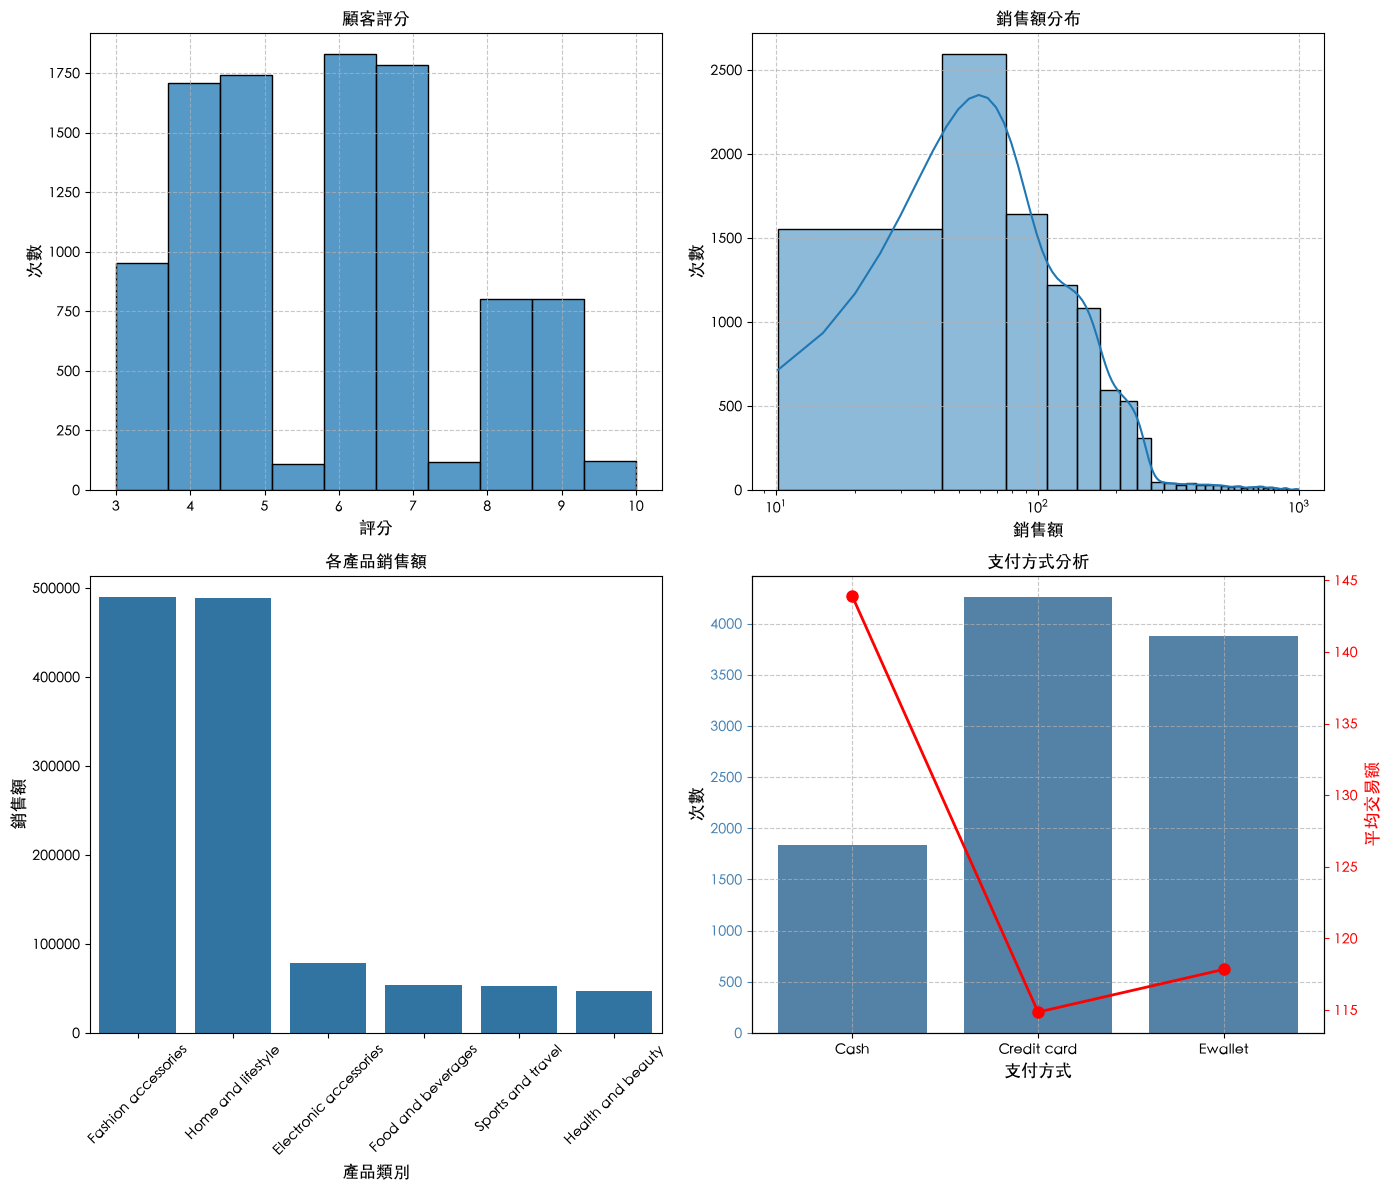

In [23]:
#評分分布

plt.rcParams["font.sans-serif"] = ["Heiti TC"]  # macOS # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False 

fig,axes= plt.subplots(2,2,figsize=(14,12))
sns.histplot(df["rating"],bins=10,ax=axes[0,0])
axes[0,0].set_title("顧客評分",fontsize=12)
axes[0,0].set_xlabel("評分",fontsize=12)
axes[0,0].set_ylabel("次數",fontsize=12)
axes[0, 0].grid(True, linestyle='--', alpha=0.7)


#銷售額分布（對數刻度）

sns.histplot(df["total"],bins=30, kde=True, ax=axes[0, 1])
axes[0,1].set_title("銷售額分布",fontsize=12)
axes[0,1].set_xlabel("銷售額",fontsize=12)
axes[0,1].set_ylabel("次數",fontsize=12)
axes[0, 1].set_xscale('log') 
axes[0,1].grid(True ,linestyle="--",alpha=0.7)


#產品種類銷售額
category_sales=df.groupby("category")["total"].sum().sort_values(ascending=False)
sns.barplot(x=category_sales.index,y=category_sales.values,ax=axes[1, 0])
axes[1, 0].set_title("各產品銷售額",fontsize=12)
axes[1, 0].set_xlabel("產品類別",fontsize=12)
axes[1, 0].set_ylabel("銷售額",fontsize=12)
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(),rotation=45)
axes[0,1].grid(True ,linestyle="--",alpha=0.7)


#支付方式計算
payment_counts=df["payment_method"].value_counts()
payment_value=df.groupby("payment_method")["total"].mean()
payment_data=pd.DataFrame({'count':payment_counts,'avg_value':payment_value})

ax4=axes[1,1]
ax4_2 = ax4.twinx()

sns.barplot(x=payment_data.index,y=payment_data["count"],ax=ax4,color='steelblue')
ax4.set_title("支付方式分析",fontsize=12)
ax4.set_xlabel("支付方式",fontsize=12)
ax4.set_ylabel("次數",fontsize=12)
ax4.tick_params(axis='y', colors='steelblue')
ax4.grid(True ,linestyle="--",alpha=0.7)

ax4_2.plot(payment_data.index, payment_data['avg_value'], 'ro-', linewidth=2, markersize=8)
ax4_2.set_ylabel('平均交易额', color='red', fontsize=12)
ax4_2.tick_params(axis='y', colors='red')




plt.tight_layout()
plt.savefig("exploratory_analysis.png")
plt.show()



In [24]:
df.to_excel("walmart_time.xlsx", index=False)

1.

In [25]:
df.to_excel("cleaned_walmart.xlsx", index=False)